## **AIRBNB: New York City Pricing, Supply-Health & Revenue Diagnostic**
### Domain: Travel & Hospitality — Revenue Management / Market Analytics
# Airbnb NYC Market Analysis: Pricing, Listing Availability and Regulatory Risks

## 1. Problem Statement

Airbnb is a popular platform for short-term rentals, but its New York City market faces several challenges related to pricing, listing availability, and government regulations.

This project aims to analyse Airbnb's NYC listings dataset to understand whether property prices are represented accurately, how many listings appear to be available for booking, and how many listings may be affected by short-term rental regulations.

Using Python, statistics, and data visualisation, the project will identify patterns, evaluate data quality, and provide useful insights to support better business decisions.



---



## 2. Business Problems

### Problem 1: Incorrect Pricing Recommendations

Airbnb's pricing recommendations may not reflect the typical prices of properties in different locations. A few very expensive properties can increase the overall average, making the recommended prices unsuitable for some hosts.

The goal is to compare the mean and median prices, understand price variations, and identify suitable pricing benchmarks for different boroughs, neighbourhoods, and room types.

### Problem 2: Unreliable Listing Availability

The total number of listings reported by Airbnb may not represent the number of properties that guests can actually book. Some listings may have no available dates, limited availability, or no recent activity.

The goal is to analyse listing availability, classify properties based on their activity and availability, and estimate how much of the reported inventory appears to be bookable.

### Problem 3: Potential Regulatory Risks

New York City has regulations that restrict certain short-term rentals, especially entire homes rented for fewer than 30 nights when the host is not present and the applicable requirements are not met.

The goal is to identify listings that may fall into this category, calculate their proportion of the total listings, and determine which boroughs and neighbourhoods have the highest concentration of potentially at-risk properties.

Since the dataset may not contain all the information needed to confirm legal violations, the results will indicate potential risks rather than confirmed violations.



---



## 3. Project Deliverables

1. **Data Quality Assessment:** Identify missing values, duplicate records, incorrect entries, and other data-quality issues. Understand the possible reasons for missing data.

2. **Pricing Analysis:** Compare the mean, median, standard deviation, MAD, percentiles, and IQR to understand typical prices, price variation, and the effect of unusually expensive properties.

3. **Outlier Detection and Data Cleaning:** Identify unusual or invalid prices, decide how to handle them, and maintain a record of the changes made to the dataset.

4. **Pricing Benchmark Tables:** Compare prices across boroughs, room types, and neighbourhoods to understand local pricing differences.

5. **Listing Availability Analysis:** Classify listings based on their availability and activity, and estimate the proportion that appears to be bookable.

6. **Revenue Estimation:** Estimate potential revenue using reasonable assumptions and explain why a simple calculation based on every listing being booked throughout the year would be misleading.

7. **Host Segmentation:** Group hosts based on the number of properties they manage and other available indicators to understand differences in hosting patterns.

8. **Regulatory Risk Analysis:** Identify potentially at-risk listings, calculate their proportion of total inventory, and analyse their distribution across boroughs and neighbourhoods.

9. **Insights and Recommendations:** Summarise the findings from each analysis and suggest improvements to pricing decisions, listing management, revenue estimation, and regulatory risk assessment.



---



## 4. Expected Outcome

The project will help explain how Airbnb listing prices vary across New York City, whether the reported listing count accurately reflects potentially bookable inventory, and where properties with potential regulatory risks are concentrated.

The analysis will provide useful business insights through statistical calculations, data visualisations, and recommendations. It will also highlight the limitations of the dataset and distinguish between findings supported by the data and assumptions that require further verification.


# STEP 0 — Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
os.makedirs('images', exist_ok=True)


pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 220)

# STEP 1 — Load and orient

In [2]:
URL = 'https://raw.githubusercontent.com/ManarOmar/New-York-Airbnb-2019/master/AB_NYC_2019.csv'

listings = pd.read_csv(URL)

print('Shape :', listings.shape)
print('Rows (listings) :', listings.shape[0])
print('Columns         :', listings.shape[1])

Shape : (48895, 16)
Rows (listings) : 48895
Columns         : 16


In [3]:
#top 5 rows
listings.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [4]:
#information about the dataset
listings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [5]:
# describe() on the numeric columns is where the pricing problem first becomes visible.
listings.describe().round(2)

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,48895.00,4.889500e+04,48895.00,48895.00,48895.00,48895.00,48895.00,38843.00,48895.00,48895.00
mean,19017143.24,6.762001e+07,40.73,-73.95,152.72,7.03,23.27,1.37,7.14,112.78
std,10983108.39,7.861097e+07,0.05,0.05,240.15,20.51,44.55,1.68,32.95,131.62
min,2539.00,2.438000e+03,40.50,-74.24,0.00,1.00,0.00,0.01,1.00,0.00
25%,9471945.00,7.822033e+06,40.69,-73.98,69.00,1.00,1.00,0.19,1.00,0.00
50%,19677284.00,3.079382e+07,40.72,-73.96,106.00,3.00,5.00,0.72,1.00,45.00
75%,29152178.50,1.074344e+08,40.76,-73.94,175.00,5.00,24.00,2.02,2.00,227.00
max,36487245.00,2.743213e+08,40.91,-73.71,10000.00,1250.00,629.00,58.50,327.00,365.00


Three things jump out:

-The mean ( 152.72)is and median is (106). That gap is the signature of a right-skewed distribution — a long tail of expensive listings.

-The standard deviation (240) is larger than the mean itself. For a price distribution that is a screaming outlier warning.

-min = $0. A listing cannot cost nothing. These are data errors.
Also note minimum_nights has a max of 1,250 — nearly three and a half years, which is not a short-term rental by any definition.

## STEP 2 — Data quality: and why the data is missing

---
Counting nulls is easy. The valuable skill is diagnosing whether missingness is random or structural, because that determines whether you can fill it, drop it, or must redesign the analysis.


In [6]:
missing_count=listings.isnull().sum()
missing_pct=(missing_count/listings.shape[0]*100).round(2)

dq=pd.DataFrame({
    'missing_rows':missing_count,
    'missing_pct':missing_pct,
    'distinct_values':listings.nunique()
})

dq.sort_values('missing_pct',ascending=False)

,missing_rows,missing_pct,distinct_values
last_review,10052,20.56,1764
reviews_per_month,10052,20.56,937
host_name,21,0.04,11452
name,16,0.03,47905
neighbourhood_group,0,0.00,5
neighbourhood,0,0.00,221
id,0,0.00,48895
host_id,0,0.00,37457
longitude,0,0.00,14718
latitude,0,0.00,19048


In [7]:
# Two columns are missing EXACTLY the same number of rows (10,052).
# That is never a coincidence - it means they share a cause. Let's find it.
print('reviews_per_month missing :', listings['reviews_per_month'].isnull().sum())
print('last_review missing:',listings['last_review'].isnull().sum())
print('Listings with ZERO reviews:',(listings['number_of_reviews']==0).sum())


reviews_per_month missing : 10052
last_review missing: 10052
Listings with ZERO reviews: 10052


In [8]:
# Test the hypothesis directly: is "reviews_per_month is null" the SAME set of rows
# as "number_of_reviews == 0"? np.all() checks that every element is True.
hypothesis = (listings['reviews_per_month'].isnull()) == (listings['number_of_reviews'] == 0)

print('Is the missingness perfectly explained by having zero reviews?')
print('  ->', np.all(hypothesis))

Is the missingness perfectly explained by having zero reviews?
  -> True


### Insight — the missingness is 100% structural, not random

`reviews_per_month` and `last_review` are missing for **exactly** the **10,052 listings
that have never received a review** — the match is perfect, not approximate.

This completely changes what we should do:

* If the missingness were **random**, we would have to impute carefully or drop rows, and
  worry about bias.
* Because it is **structural**, the "missing" value is actually a **known value**:
  a listing with zero reviews has **0.0 reviews per month**. Nothing is unknown.

`last_review` is different — for a never-reviewed listing there genuinely *is* no last
review date. That must stay missing; inventing a date would be fabricating data.

**And there is a business finding hiding in here:** **10,052 listings — 20.6% of NYC
supply — have never been reviewed at all.** On Airbnb, a review is the closest available
proxy for a completed stay. One in five listings may never have hosted a single guest.

### Recommendation
1. `fillna(0)` on `reviews_per_month` — this is *recovering a known value*, not imputing.
2. **Leave `last_review` null** and handle it explicitly wherever it is used.
3. Escalate the 20.6% never-reviewed figure to Operations — it is the first hard evidence
   for **Problem 2** (that headline supply is overstated).

In [9]:
# Recover the known value. fillna(0) is correct here BECAUSE we proved the cause.
listings['reviews_per_month'] = listings['reviews_per_month'].fillna(0)

# host_name and name are cosmetic text fields - fill with an explicit marker so
# downstream groupby operations do not silently drop these rows.
listings['host_name'] = listings['host_name'].fillna('Unknown')
listings['name']      = listings['name'].fillna('No title provided')

print('Remaining nulls after treatment:')
print(listings.isnull().sum().loc[listings.isnull().sum() > 0])
print()
print('(last_review remains null by design - a never-reviewed listing has no last review.)')

Remaining nulls after treatment:
last_review    10052
dtype: int64

(last_review remains null by design - a never-reviewed listing has no last review.)


## STEP 3 — Descriptive statistics: which average should drive pricing?

In [10]:
price = listings['price']

# ---- MEASURES OF CENTRAL TENDENCY --------------------------------------------------
print('=== CENTRAL TENDENCY ===')
print('Mean   (not robust) : $', round(price.mean(), 2))
print('Median (robust)     : $', price.median())
print('Gap                 : $', round(price.mean() - price.median(), 2),
      '->', round((price.mean() / price.median() - 1) * 100, 1), '% higher')
print()

# Mode: the most FREQUENTLY occurring price. value_counts() gives it to us directly.
print('Most common price points (the mode and its neighbours):')
print(price.value_counts().head(8))

=== CENTRAL TENDENCY ===
Mean   (not robust) : $ 152.72
Median (robust)     : $ 106.0
Gap                 : $ 46.72 -> 44.1 % higher

Most common price points (the mode and its neighbours):
price
100    2051
150    2047
50     1534
60     1458
200    1401
75     1370
80     1272
65     1190
Name: count, dtype: int64


In [11]:
# ---- MEASURES OF VARIABILITY / DISPERSION ------------------------------------------
print('=== VARIABILITY ===')
print()
print('NOT robust (both are built on the mean):')
print('  Standard deviation : $', round(price.std(), 2))
print('  Variance           : $', round(price.std() ** 2, 2))
print()
print('ROBUST (both are built on the median / sorted order):')
print('  Median Absolute Deviation (MAD) : $', round(stats.median_abs_deviation(price), 2))
print('  Interquartile Range (IQR)       : $', round(stats.iqr(price), 2))
print()
print('Ratio std / MAD :', round(price.std() / stats.median_abs_deviation(price), 1), 'x')

=== VARIABILITY ===

NOT robust (both are built on the mean):
  Standard deviation : $ 240.15
  Variance           : $ 57674.03

ROBUST (both are built on the median / sorted order):
  Median Absolute Deviation (MAD) : $ 46.0
  Interquartile Range (IQR)       : $ 106.0

Ratio std / MAD : 5.2 x


### Insight — the robust and non-robust estimators disagree violently

| Estimator | Value | Robust to outliers? |
|---|---|---|
| Mean | **$152.72** | ✗ No |
| Median | **$106.00** | ✓ Yes |
| Standard deviation | **$240.15** | ✗ No |
| **MAD** | **$46.00** | ✓ Yes |
| IQR | $106.00 | ✓ Yes |

**The standard deviation is 5.2× the MAD.** If the price distribution were well behaved,
these two would be in the same ballpark. A 5× divergence is conclusive proof that a small
number of extreme values is dominating every mean-based statistic.

The mode is also revealing: the most common prices are **$150, $100, $50, $60, $200** —
hosts anchor on **round numbers**, they do not price continuously.

### Recommendation
**Airbnb's pricing guidance must be built on the median and MAD, not the mean and standard
deviation.** Concretely:

* A "typical NYC price" of **$152.72** (mean) over-advises the majority of hosts. The
  honest typical price is **$106** (median).
* A "typical variation" of **±$240** (std) is nonsense — it implies prices routinely swing
  negative. The honest spread is **±$46** (MAD).

This single change directly addresses the Bronx hosts' complaint that guidance is
"laughably high": for them, it *was*.

# STEP 4 — Percentiles, the IQR rule, and an outlier policy

In [12]:
# Percentiles are the most outlier-immune way to describe a distribution.
# np.percentile(data, p) -> the value below which p% of observations fall.
for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]:
    print('  ' + str(p).rjust(2) + 'th percentile : $', round(np.percentile(price, p), 1))

   1th percentile : $ 30.0
   5th percentile : $ 40.0
  10th percentile : $ 49.0
  25th percentile : $ 69.0
  50th percentile : $ 106.0
  75th percentile : $ 175.0
  90th percentile : $ 269.0
  95th percentile : $ 355.0
  99th percentile : $ 799.0


In [13]:
# Quantiles Q1/Q2/Q3 are just the 25th/50th/75th percentiles.
# .quantile() is the Pandas equivalent of np.percentile().
Q1 = price.quantile(0.25)
Q2 = price.quantile(0.50)
Q3 = price.quantile(0.75)
IQR = Q3 - Q1

print('Q1 (25th) : $', Q1)
print('Q2 (50th) : $', Q2, ' <- same as the median')
print('Q3 (75th) : $', Q3)
print('IQR       : $', IQR, ' (the range containing the middle 50% of listings)')
print()
print('Cross-check with scipy.stats.iqr :', stats.iqr(price))

Q1 (25th) : $ 69.0
Q2 (50th) : $ 106.0  <- same as the median
Q3 (75th) : $ 175.0
IQR       : $ 106.0  (the range containing the middle 50% of listings)

Cross-check with scipy.stats.iqr : 106.0


In [14]:
# ---- THE 1.5 x IQR OUTLIER RULE ----------------------------------------------------
# Anything below Q1 - 1.5*IQR or above Q3 + 1.5*IQR is flagged as an outlier.
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

print('Lower fence : $', lower_fence)
print('Upper fence : $', upper_fence)
print()

high_outliers = listings.loc[listings['price'] > upper_fence]
low_outliers  = listings.loc[listings['price'] < lower_fence]

print('Listings above the upper fence :', high_outliers.shape[0],
      '->', round(high_outliers.shape[0] / listings.shape[0] * 100, 2), '%')
print('Listings below the lower fence :', low_outliers.shape[0])

Lower fence : $ -90.0
Upper fence : $ 334.0

Listings above the upper fence : 2972 -> 6.08 %
Listings below the lower fence : 0


### Insight — read the fences critically, do not apply them mechanically

* **Upper fence = $334.** 2,972 listings (**6.08%**) price above it.
* **Lower fence = −$90.** This is **mathematically valid but physically meaningless** —
  no price can be negative, so the rule flags *zero* low outliers.

That second point matters. The 1.5×IQR rule assumes a roughly symmetric distribution.
Applied blindly to skewed, strictly-positive data like prices, it produces a nonsense
lower bound. **The statistic did not fail; the assumption behind it did.** An analyst who
reports "no low-side outliers" without noticing the negative fence has not actually
checked anything.

* And the genuinely invalid records are the **11 listings priced at $0** — which the IQR
  rule **completely misses**, because $0 sits comfortably above −$90.

### Recommendation — a two-part outlier policy

| Category | Count | Treatment | Why |
|---|---|---|---|
| **`price == 0`** | 11 | **Remove** | Impossible value. A genuine data error. |
| **`price > $334`** | 2,972 | **Keep, but exclude from pricing guidance** | These are *real* luxury listings, not errors. Deleting them would destroy legitimate market information. |

The distinction is important: **an outlier is not the same thing as an error.** A $10,000
Tribeca penthouse is a real listing and belongs in market-size analysis. It just must not
be allowed to set the suggested price for a Bronx private room.

In [15]:
# Build the analysis frame, and log every row removed so the cleaning is auditable.
rows_start = listings.shape[0]

# 1) Remove impossible prices
listings_valid = listings.loc[listings['price'] > 0]
removed_zero = rows_start - listings_valid.shape[0]

# 2) Create the guidance frame (excludes luxury tail, keeps it available in listings_valid)
guidance = listings_valid.loc[listings_valid['price'] <= upper_fence]
removed_lux = listings_valid.shape[0] - guidance.shape[0]

# copy() protects us from accidentally modifying a slice of the parent DataFrame
guidance = guidance.copy()

cleaning_log = pd.DataFrame({
    'step': ['Raw listings loaded',
             'Removed price == $0 (data errors)',
             'Excluded price > $334 from guidance (real but atypical)',
             'Final guidance frame'],
    'rows': [rows_start, removed_zero, removed_lux, guidance.shape[0]]
})
cleaning_log

,step,rows
0,Raw listings loaded,48895
1,Removed price == $0 (data errors),11
2,Excluded price > $334 from guidance (real but ...,2972
3,Final guidance frame,45912


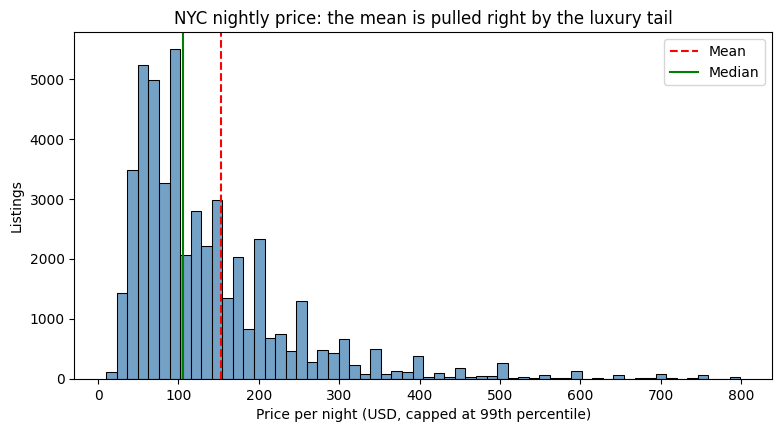

In [16]:
#1. Mean vs. median on the price distribution
p99 = listings_valid['price'].quantile(0.99)
capped = listings_valid[listings_valid['price'] <= p99]

plt.figure(figsize=(9, 4.5))
sns.histplot(capped['price'], bins=60, color='steelblue')
plt.axvline(listings_valid['price'].mean(), color='red', linestyle='--', label='Mean')
plt.axvline(listings_valid['price'].median(), color='green', label='Median')
plt.title('NYC nightly price: the mean is pulled right by the luxury tail')
plt.xlabel('Price per night (USD, capped at 99th percentile)')
plt.ylabel('Listings')
plt.legend()
plt.savefig('images/chart1_price_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [17]:
# Confirm the effect of the cleaning on the headline statistics.
print('                     RAW        GUIDANCE FRAME')
print('Listings    :', str(listings.shape[0]).rjust(10), str(guidance.shape[0]).rjust(15))
print('Mean price  : $', str(round(listings['price'].mean(), 2)).rjust(8),
      ' $', str(round(guidance['price'].mean(), 2)).rjust(12))
print('Median price: $', str(listings['price'].median()).rjust(8),
      ' $', str(guidance['price'].median()).rjust(12))
print('Std dev     : $', str(round(listings['price'].std(), 2)).rjust(8),
      ' $', str(round(guidance['price'].std(), 2)).rjust(12))
print('MAD         : $', str(round(stats.median_abs_deviation(listings['price']), 2)).rjust(8),
      ' $', str(round(stats.median_abs_deviation(guidance['price']), 2)).rjust(12))

                     RAW        GUIDANCE FRAME
Listings    :      48895           45912
Mean price  : $   152.72  $        120.0
Median price: $    106.0  $        100.0
Std dev     : $   240.15  $        68.13
MAD         : $     46.0  $         42.0


<Axes: >

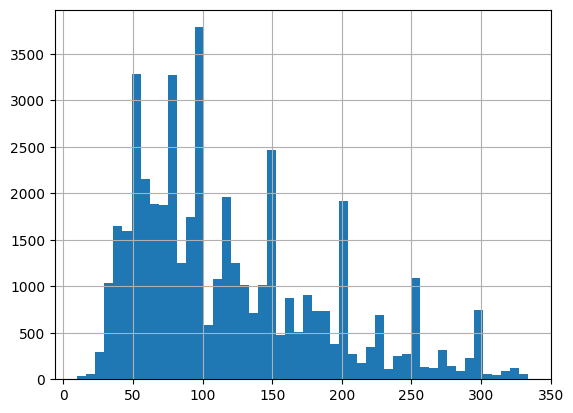

In [18]:
# A histogram of the guidance frame shows a distribution we can actually reason about.
guidance['price'].hist(bins=50)

### Insight — the effect of the outlier policy

| Statistic | Raw (48,895) | Guidance frame (45,912) | Change |
|---|---|---|---|
| Mean | $152.72 | **$120.00** | −21% |
| Median | $106.00 | **$100.00** | **−5.7%** |
| Std dev | $240.15 | **$68.13** | **−71.6%** |
| MAD | $46.00 | **$42.00** | −8.7% |

Removing 6.1% of listings cut the standard deviation by **71.6%** ($240.15 → $68.13) while
barely moving the median ($106 → $100, just −5.7%). That asymmetry is the proof that the
policy worked: we removed *volatility*, not *signal*. Note the robust estimators (median,
MAD) hardly moved at all — which is exactly what "robust" means, and a useful sanity check
that our outlier policy did not accidentally delete the middle of the market.

Critically, in the guidance frame the mean and median are now within 20% of each other
instead of 44% apart — the distribution is still right-skewed, but no longer pathological.

### Recommendation
Adopt the **guidance frame** as the basis for Smart Pricing, and keep the full
`listings_valid` frame for market-sizing and competitive analysis. Publish both
denominators so nobody accidentally compares one to the other.

## STEP 5 — Pricing benchmarks by borough and room type


---
Now we can answer the hosts' actual question: "what should a listing like mine cost?"


In [19]:
print('Listings by borough:')
print(guidance['neighbourhood_group'].value_counts())
print()
print('Listings by room type:')
print(guidance['room_type'].value_counts())

Listings by borough:
neighbourhood_group
Manhattan        19505
Brooklyn         19406
Queens            5567
Bronx             1069
Staten Island      365
Name: count, dtype: int64

Listings by room type:
room_type
Entire home/apt    22787
Private room       21989
Shared room         1136
Name: count, dtype: int64


In [20]:
# pivot_table gives us the classic two-dimensional benchmark grid.
# We use MEDIAN because Step 3 proved the mean is unreliable for prices.
median_grid = guidance.pivot_table(values='price',
                                   index='neighbourhood_group',
                                   columns='room_type',
                                   aggfunc='median',
                                   fill_value=0)
print('MEDIAN nightly price ($) - use THIS for host guidance:')
median_grid

MEDIAN nightly price ($) - use THIS for host guidance:


room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,100.0,53.0,40.0
Brooklyn,140.0,64.0,36.0
Manhattan,175.0,89.0,67.0
Queens,120.0,59.0,37.0
Staten Island,100.0,50.0,30.0


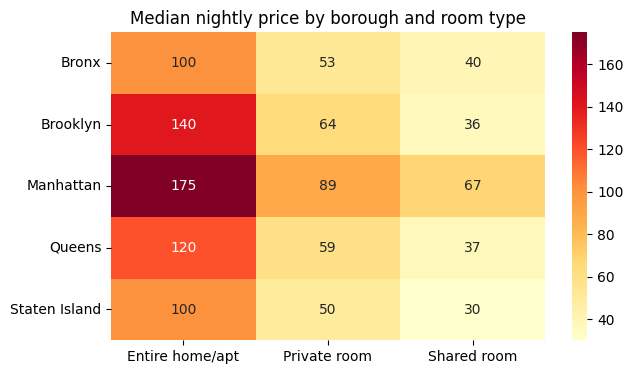

In [21]:
plt.figure(figsize=(7, 4))
sns.heatmap(median_grid, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Median nightly price by borough and room type')
plt.xlabel('')
plt.ylabel('')
plt.savefig('images/chart2_median_grid.png', dpi=150, bbox_inches='tight')
plt.show()

In [22]:
# The mean grid, shown only to demonstrate how much it inflates the guidance.
mean_grid = guidance.pivot_table(values='price',
                                 index='neighbourhood_group',
                                 columns='room_type',
                                 aggfunc='mean',
                                 fill_value=0).round(1)
print('MEAN nightly price ($) - inflated, do NOT use for guidance:')
mean_grid

MEAN nightly price ($) - inflated, do NOT use for guidance:


room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,112.2,60.7,47.3
Brooklyn,148.2,70.3,48.3
Manhattan,181.7,98.1,75.9
Queens,131.3,65.7,47.0
Staten Island,121.1,62.3,57.4


In [23]:
# Quantify the over-advice: how much higher is the mean than the median in each cell?
inflation = (mean_grid - median_grid).round(1)
print('Dollars by which MEAN over-states MEDIAN in each segment:')
inflation

Dollars by which MEAN over-states MEDIAN in each segment:


room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,12.2,7.7,7.3
Brooklyn,8.2,6.3,12.3
Manhattan,6.7,9.1,8.9
Queens,11.3,6.7,10.0
Staten Island,21.1,12.3,27.4


In [24]:
# Supply volume per cell, so we know which benchmarks are statistically reliable.
volume_grid = guidance.pivot_table(values='id',
                                   index='neighbourhood_group',
                                   columns='room_type',
                                   aggfunc='count',
                                   fill_value=0)
print('Number of listings behind each benchmark:')
volume_grid

Number of listings behind each benchmark:


room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,363,647,59
Brooklyn,8941,10056,409
Manhattan,11293,7747,465
Queens,2022,3351,194
Staten Island,168,188,9


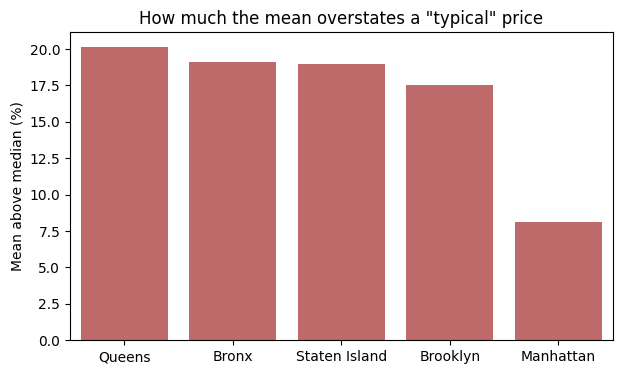

In [25]:
over = guidance.groupby('neighbourhood_group')['price'].agg(['mean', 'median'])
over['overstatement_pct'] = (over['mean'] / over['median'] - 1) * 100
over = over.sort_values('overstatement_pct', ascending=False)

plt.figure(figsize=(7, 4))
sns.barplot(x=over.index, y=over['overstatement_pct'], color='indianred')
plt.title('How much the mean overstates a "typical" price')
plt.xlabel('')
plt.ylabel('Mean above median (%)')
plt.savefig('images/chart3_mean_overstatement.png', dpi=150, bbox_inches='tight')
plt.show()

### Insight — the pricing grid

**Median nightly price ($):**

| Borough | Entire home/apt | Private room | Shared room |
|---|---|---|---|
| **Manhattan** | **175** | **89** | **67** |
| Brooklyn | 140 | 64 | 36 |
| Queens | 120 | 59 | 37 |
| Bronx | 100 | 53 | 40 |
| Staten Island | 100 | 50 | 30 |

Three findings that matter commercially:

1. **Room type matters more than borough.** An entire home in the *cheapest* borough
   ($100, Bronx/Staten Island) still commands more than a private room in the *most
   expensive* one ($89, Manhattan). Any guidance engine that weights location above
   room type is mis-specified.
2. **Manhattan carries a large premium at every room type** — 25% above Brooklyn for
   entire homes, 39% above for private rooms.
3. **Shared rooms are erratic** (Bronx $40 > Brooklyn $36) because the sample is tiny —
   only 1,160 shared rooms exist in the whole city, so some cells rest on a handful of
   listings.

**And the direct answer to the hosts' complaint — with a twist we did not expect:**

The mean over-states the median in **every single cell**, but *by how much* varies
systematically. Reading the `inflation` table:

| Borough | Entire home | Private room | Shared room |
|---|---|---|---|
| **Staten Island** | **+$21.1** | **+$12.3** | **+$27.4** |
| Bronx | +$12.2 | +$7.7 | +$7.3 |
| Queens | +$11.3 | +$6.7 | +$10.0 |
| Brooklyn | +$8.2 | +$6.3 | +$12.3 |
| **Manhattan** | **+$6.7** | +$9.1 | +$8.9 |

**The over-statement is largest in the cheapest boroughs and smallest in Manhattan.**
That is precisely why the complaints came from the Bronx and not from Tribeca: in a
low-price market, even a modest local luxury tail distorts the mean by a large *percentage*
of a small number. On a $100 Bronx entire home, +$12 is a 12% over-quote; on a $175
Manhattan home, +$6.70 is under 4%.

**Supply volume warns us where not to publish at all:** Staten Island has just **9 shared
rooms** and the Bronx **59** in the entire guidance frame.

### Recommendation
1. **Rebuild Smart Pricing on the median grid**, segmented by **room type first, borough
   second**.
2. **Suppress guidance entirely where cell volume is thin** — Staten Island shared rooms
   (9 listings), Bronx shared rooms (59), Staten Island entire homes (168). A benchmark
   from 9 listings is noise presented as advice; better to show nothing than something wrong.
3. **Prioritise the fix by borough, not uniformly.** The mean-based engine hurt outer-borough
   hosts several times more than Manhattan hosts, so outer-borough host satisfaction should
   improve most — and that is where Airbnb most needs supply growth.
4. Publish the **MAD per cell** alongside the median as a legitimate price *range*, rather
   than a single point estimate.

## STEP 6 — Neighbourhood-level benchmarks (with a reliability gate)

In [26]:
# groupby + aggregate({}) computes several statistics per neighbourhood in one pass.
nb = guidance.groupby('neighbourhood').aggregate({
    'price': ['median', 'mean', 'count'],
    'availability_365': 'median',
    'number_of_reviews': 'median'
})

print('Multi-level columns produced by aggregate():')
print(nb.columns)
nb.head()

Multi-level columns produced by aggregate():
MultiIndex([(            'price', 'median'),
            (            'price',   'mean'),
            (            'price',  'count'),
            ( 'availability_365', 'median'),
            ('number_of_reviews', 'median')],
           )


price                   availability_365 number_of_reviews
              median        mean count           median            median
neighbourhood                                                            
Allerton        63.0   78.756098    41            157.0              26.0
Arden Heights   72.5   67.250000     4             30.5               5.0
Arrochar        65.0   89.500000    20            301.0              11.5
Arverne        110.0  135.097222    72            155.5              16.5
Astoria         85.0   96.747463   887             35.0               5.0

In [27]:
# Flatten the multi-index columns by joining the tuple levels with '_',
# then reset_index() to turn the grouping key back into a normal column.
nb.columns = ['_'.join(col) for col in nb.columns]
nb = nb.reset_index()
nb.columns = ['neighbourhood', 'median_price', 'mean_price', 'listings',
              'median_availability', 'median_reviews']

nb['mean_price'] = nb['mean_price'].round(1)
print('Total neighbourhoods :', nb.shape[0])
nb.head()

Total neighbourhoods : 219


,neighbourhood,median_price,mean_price,listings,median_availability,median_reviews
0,Allerton,63.0,78.8,41,157.0,26.0
1,Arden Heights,72.5,67.2,4,30.5,5.0
2,Arrochar,65.0,89.5,20,301.0,11.5
3,Arverne,110.0,135.1,72,155.5,16.5
4,Astoria,85.0,96.7,887,35.0,5.0


In [28]:
# RELIABILITY GATE: a benchmark computed from 4 listings is not a benchmark.
# We require at least 100 listings before we are willing to publish a price.
MIN_LISTINGS = 100

reliable   = nb.loc[nb['listings'] >= MIN_LISTINGS]
unreliable = nb.loc[nb['listings'] < MIN_LISTINGS]

print('Neighbourhoods with >=', MIN_LISTINGS, 'listings :', reliable.shape[0])
print('Neighbourhoods below the gate            :', unreliable.shape[0])
print('Share of LISTINGS covered by reliable neighbourhoods :',
      round(reliable['listings'].sum() / nb['listings'].sum() * 100, 1), '%')

Neighbourhoods with >= 100 listings : 65
Neighbourhoods below the gate            : 154
Share of LISTINGS covered by reliable neighbourhoods : 91.4 %


In [29]:
# The premium end of the market
print('TOP 15 most expensive reliable neighbourhoods (by median price):')
reliable.sort_values('median_price', ascending=False).head(15)

TOP 15 most expensive reliable neighbourhoods (by median price):


,neighbourhood,median_price,mean_price,listings,median_availability,median_reviews
196,Tribeca,225.0,212.5,107,38.0,2.0
208,West Village,195.0,193.1,649,3.0,5.0
73,Financial District,189.0,184.0,652,236.0,2.0
91,Greenwich Village,177.5,180.3,342,1.0,4.0
126,Midtown,175.0,181.1,1144,120.5,2.0
34,Chelsea,175.0,178.8,950,28.5,4.0
136,Murray Hill,175.0,180.0,426,144.5,1.0
190,Theater District,169.0,177.0,243,257.0,1.0
144,Nolita,160.0,169.0,225,1.0,6.0
177,SoHo,159.5,164.4,268,30.0,5.0


In [30]:
# The value end of the market
print('BOTTOM 10 cheapest reliable neighbourhoods (by median price):')
reliable.sort_values('median_price', ascending=True).head(10)

BOTTOM 10 cheapest reliable neighbourhoods (by median price):


,neighbourhood,median_price,mean_price,listings,median_availability,median_reviews
20,Borough Park,53.5,63.1,136,166.0,5.0
68,Elmhurst,59.0,77.6,235,89.0,6.0
59,East Elmhurst,60.0,77.8,184,150.0,26.0
165,Ridgewood,60.0,75.2,420,63.5,3.0
218,Woodside,60.0,78.6,231,89.0,3.0
77,Flushing,62.0,78.1,413,126.0,19.0
122,Maspeth,65.0,83.6,110,185.5,7.5
28,Bushwick,65.0,80.0,2435,18.0,4.0
174,Sheepshead Bay,65.0,83.6,159,111.0,5.0
52,Cypress Hills,66.5,77.0,130,160.0,17.0


### Insight — neighbourhood benchmarks

* Only **65 of 219 neighbourhoods** clear the 100-listing reliability gate — but those 65
  contain **91.4% of all listings**. So the gate costs us under 9% of coverage while
  removing a large amount of noise. That is an excellent trade.
* **The premium tier is Lower/West Manhattan:** Tribeca **$225**, West Village $195,
  Financial District $189, Greenwich Village $177.50, Midtown $175, Chelsea $175,
  Murray Hill $175, Theater District $169.
* **Tribeca at $225 is 2.25× the citywide median of $100** — and note this is *within* the
  guidance frame, i.e. after luxury listings were excluded. The premium is structural, not
  an outlier artifact.
* Brooklyn's premium pockets (Brooklyn Heights $150, Boerum Hill $150) now match mid-tier
  Manhattan — gentrification pressure showing up directly in nightly rates.
* **The `median_availability` column reveals two completely different business models at
  similar price points.** Compare:
  * **Financial District** — $189/night, median availability **236 nights**
  * **West Village** — $195/night, median availability **3 nights**

  Same price, opposite behaviour. FiDi listings sit open almost all year (investor- or
  corporate-let inventory, priced and managed like hotel stock). West Village listings are
  closed nearly all year (residents letting their own home occasionally). **Price alone
  cannot distinguish these; availability can.**

### Recommendation
1. **Ship neighbourhood-level guidance only for the 65 gated neighbourhoods.** For the
   remaining 154, fall back to the borough × room-type grid from Step 5 — a standard,
   defensible hierarchy: *the most specific reliable level wins.*
2. **Tribeca / West Village / Financial District are the highest-yield host-acquisition
   targets** — each new listing there is worth roughly 2× a median listing in nightly rate.
3. **Segment guidance by availability pattern, not just location.** A FiDi-style always-open
   operator needs yield-management advice (dynamic rates, occupancy optimisation); a
   West-Village-style occasional host needs a simple, stable price. Giving both the same
   recommendation serves neither.
4. Re-run this gate quarterly — neighbourhoods cross the 100-listing threshold as supply
   grows, and guidance coverage should expand automatically with it.

## STEP 7 — SUPPLY HEALTH (and the second trap in this dataset)

---
Now we attack Problem 2: is the headline "48,895 listings" real?


In [31]:
print('Availability (nights bookable in the next 365 days):')
print(listings_valid['availability_365'].describe().round(1))

Availability (nights bookable in the next 365 days):
count    48884.0
mean       112.8
std        131.6
min          0.0
25%          0.0
50%         45.0
75%        227.0
max        365.0
Name: availability_365, dtype: float64


In [32]:
# The distribution above has a median of 45 but a 25th percentile of 0.
# That means at least a quarter of listings are bookable ZERO nights. Investigate.
zero_avail = (listings_valid['availability_365'] == 0).sum()
full_avail = (listings_valid['availability_365'] == 365).sum()

print('Listings with availability_365 == 0   :', zero_avail,
      '->', round(zero_avail / listings_valid.shape[0] * 100, 2), '%')
print('Listings with availability_365 == 365 :', full_avail,
      '->', round(full_avail / listings_valid.shape[0] * 100, 2), '%')

Listings with availability_365 == 0   : 17530 -> 35.86 %
Listings with availability_365 == 365 : 1295 -> 2.65 %


### 🚨 Insight — `availability_365 == 0` is ambiguous, and the naive reading is catastrophic

**35.9% of listings (17,533) show zero available nights.**

There are two possible explanations, and they point in **opposite** directions:

| Interpretation | What it would mean | Implied occupancy |
|---|---|---|
| **A: Fully booked** | The listing is so popular every night is sold | **100%** |
| **B: Calendar blocked / inactive** | The host has switched the listing off, gone dormant, or abandoned it | **0%** |

If we naively compute `booked_nights = 365 - availability_365`, we assign these 17,533
listings **365 booked nights each** — a perfect 100% annual occupancy rate. **That is not
plausible for a third of a city's inventory.** Real Airbnb occupancy in dense urban
markets runs closer to 40–70%.

**We can test which interpretation is right** by cross-checking against review activity:
a genuinely fully-booked listing generates reviews. A dormant one does not.

In [33]:
# Cross-check availability against review activity to break the ambiguity.
zero_avail_rows = listings_valid.loc[listings_valid['availability_365'] == 0]
some_avail_rows = listings_valid.loc[listings_valid['availability_365'] > 0]

print('=== LISTINGS WITH ZERO AVAILABILITY ===')
print('Count                     :', zero_avail_rows.shape[0])
print('Median reviews_per_month  :', zero_avail_rows['reviews_per_month'].median())
print('Median number_of_reviews  :', zero_avail_rows['number_of_reviews'].median())
print('Share with ZERO reviews   :',
      round((zero_avail_rows['number_of_reviews'] == 0).mean() * 100, 1), '%')
print()
print('=== LISTINGS WITH SOME AVAILABILITY ===')
print('Count                     :', some_avail_rows.shape[0])
print('Median reviews_per_month  :', some_avail_rows['reviews_per_month'].median())
print('Median number_of_reviews  :', some_avail_rows['number_of_reviews'].median())
print('Share with ZERO reviews   :',
      round((some_avail_rows['number_of_reviews'] == 0).mean() * 100, 1), '%')

=== LISTINGS WITH ZERO AVAILABILITY ===
Count                     : 17530
Median reviews_per_month  : 0.08
Median number_of_reviews  : 2.0
Share with ZERO reviews   : 27.6 %

=== LISTINGS WITH SOME AVAILABILITY ===
Count                     : 31354
Median reviews_per_month  : 0.92
Median number_of_reviews  : 10.0
Share with ZERO reviews   : 16.6 %


### Insight — the evidence says **Interpretation B: these listings are inactive**

| Metric | Zero availability (17,530) | Some availability (31,354) |
|---|---|---|
| Median reviews **per month** | **0.08** | **0.92** — *11.5× higher* |
| Median lifetime reviews | **2** | **10** — *5× higher* |
| Share never reviewed | **27.6%** | 16.6% |

The verdict is not close. The zero-availability cohort gets **one review every ~12 months**;
the available cohort gets **roughly one a month**.

If these listings were *fully booked*, they would be the **most** reviewed listings in the
city. They are the least. **`availability_365 == 0` predominantly means "calendar closed /
listing dormant", not "sold out".**

### Recommendation
**Classify supply explicitly rather than treating all 48,895 rows as active inventory.**
Any forecast, revenue model or market-share number that uses the raw listing count is
**overstating bookable supply by roughly a third**. Build the classification below and
make it the standard denominator.

In [34]:
# Build an explicit supply-health classification using a custom function + apply().
# Defining a named function (rather than nesting np.where five deep) keeps the
# business rules readable and reviewable by a non-analyst.
def classify_supply(row):
    if row['availability_365'] == 0:
        return 'Inactive - calendar closed'
    if row['number_of_reviews'] == 0:
        return 'Unproven - never reviewed'
    if row['reviews_per_month'] < 0.5:
        return 'Low activity'
    return 'Active'

# axis=1 applies the function to each ROW (giving us access to several columns at once).
listings_valid = listings_valid.copy()
listings_valid['supply_health'] = listings_valid.apply(classify_supply, axis=1)

health = listings_valid['supply_health'].value_counts()
health_pct = (health / listings_valid.shape[0] * 100).round(2)

print(health)
print()
print('Share (%):')
print(health_pct)

supply_health
Active                        19141
Inactive - calendar closed    17530
Low activity                   7006
Unproven - never reviewed      5207
Name: count, dtype: int64

Share (%):
supply_health
Active                        39.16
Inactive - calendar closed    35.86
Low activity                  14.33
Unproven - never reviewed     10.65
Name: count, dtype: float64


In [35]:
# Supply health by borough - where is the dead inventory concentrated?
health_by_borough = listings_valid.pivot_table(values='id',
                                               index='neighbourhood_group',
                                               columns='supply_health',
                                               aggfunc='count',
                                               fill_value=0)
print('Listing counts by borough x supply health:')
print(health_by_borough)
print()

# Convert to ROW percentages so boroughs of very different sizes are comparable.
#
# HOW: groupby().transform('count') broadcasts each borough's TOTAL listing count back
# onto every one of its rows. So 100 / that total is one listing's percentage weight.
# Summing those weights inside pivot_table gives each cell as a % of its borough.
listings_valid['pct_weight_borough'] = 100 / listings_valid.groupby(
                                             'neighbourhood_group')['id'].transform('count')

health_pct_borough = listings_valid.pivot_table(values='pct_weight_borough',
                                                index='neighbourhood_group',
                                                columns='supply_health',
                                                aggfunc='sum',
                                                fill_value=0).round(1)
print('Supply health by borough (% of that borough\'s listings):')
health_pct_borough

Listing counts by borough x supply health:
supply_health        Active  Inactive - calendar closed  Low activity  Unproven - never reviewed
neighbourhood_group                                                                             
Bronx                   605                         177           150                        158
Brooklyn               7781                        7842          2876                       1596
Manhattan              7633                        8101          3180                       2746
Queens                 2883                        1368           752                        663
Staten Island           239                          42            48                         44

Supply health by borough (% of that borough's listings):


supply_health,Active,Inactive - calendar closed,Low activity,Unproven - never reviewed
neighbourhood_group,,,,
Bronx,55.5,16.2,13.8,14.5
Brooklyn,38.7,39.0,14.3,7.9
Manhattan,35.2,37.4,14.7,12.7
Queens,50.9,24.1,13.3,11.7
Staten Island,64.1,11.3,12.9,11.8


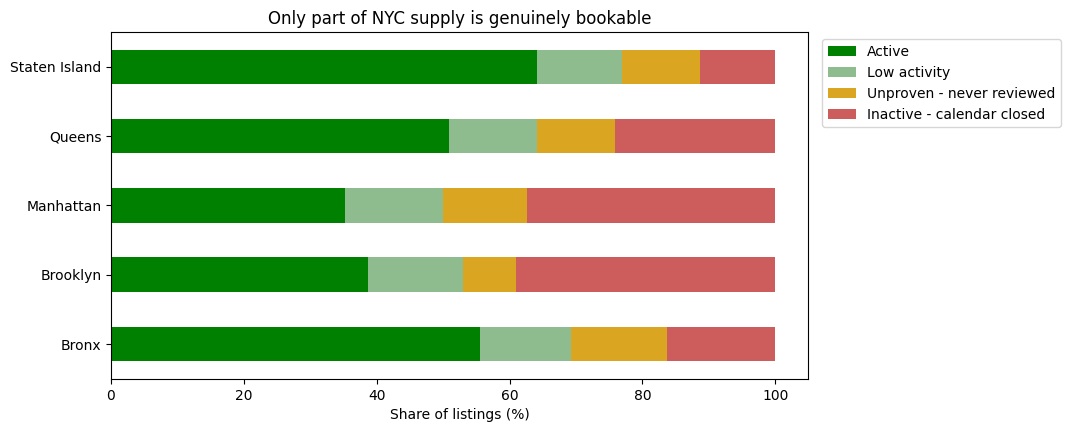

In [36]:
order = ['Active', 'Low activity', 'Unproven - never reviewed', 'Inactive - calendar closed']

health = listings_valid.pivot_table(index='neighbourhood_group',
                                    columns='supply_health',
                                    values='id', aggfunc='count', fill_value=0)[order]
health = health.div(health.sum(axis=1), axis=0) * 100

health.plot(kind='barh', stacked=True, figsize=(9, 4.5),
            color=['green', 'darkseagreen', 'goldenrod', 'indianred'])
plt.title('Only part of NYC supply is genuinely bookable')
plt.xlabel('Share of listings (%)')
plt.ylabel('')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.savefig('images/chart4_supply_health.png', dpi=150, bbox_inches='tight')
plt.show()

### Insight — only 39% of NYC supply is genuinely bookable

| Supply health | Listings | Share |
|---|---|---|
| **Active** | **19,141** | **39.16%** |
| Inactive – calendar closed | 17,530 | 35.86% |
| Low activity | 7,006 | 14.33% |
| Unproven – never reviewed | 5,207 | 10.65% |

**The headline "48,895 listings" is really ~19,100 genuinely active listings — an
overstatement of roughly 2.6×.**

The borough breakdown is counter-intuitive and commercially important:

| Borough | Active % | Inactive % |
|---|---|---|
| Staten Island | **64.1%** | 11.3% |
| Bronx | **55.5%** | 16.2% |
| Queens | 50.9% | 24.1% |
| Brooklyn | 38.7% | **39.0%** |
| **Manhattan** | **35.2%** | **37.4%** |

**The two premium boroughs have the *worst* supply health.** Manhattan — the most valuable
market — has the lowest active share (35.2%) and the second-highest dead inventory. The
cheap outer boroughs are the healthiest.

The likely reason is the same one Step 10 quantifies: Manhattan and Brooklyn are where the
regulatory pressure is greatest, so hosts there close calendars rather than delist. Dead
inventory is concentrated exactly where the legal risk is.

### Recommendation
1. **Replace "total listings" with "active listings" as the headline supply KPI**
   everywhere — market dashboards, Finance forecasts, and any external market-share claim.
   The correction is **2.6×**, not a rounding difference. This is the direct answer to Problem 2.
   *Also report it by borough*, because a single citywide number hides the fact that the
   most valuable borough has the worst supply health.
2. **Launch a host-reactivation programme** targeted at the *Inactive – calendar closed*
   cohort. These hosts have already completed onboarding and listing creation — the
   expensive part — so reactivating one is far cheaper than acquiring a new host.
3. **Treat the *Unproven – never reviewed* cohort as an onboarding-funnel failure.**
   One in five listings has never hosted a guest. That is a conversion problem (pricing,
   photos, search ranking for new listings), not a supply problem.
4. **Report supply health by borough** in the market dashboard so Operations can target
   reactivation where the dead inventory actually is.

## STEP 8 — Revenue estimation, done honestly

---
We now build a revenue estimate — and we build the wrong one first, on purpose, so the difference is visible and documented.



In [37]:
# ---- VERSION 1: THE NAIVE ESTIMATE (which we will reject) --------------------------
naive = listings_valid.copy()
naive['booked_nights'] = 365 - naive['availability_365']
naive['annual_revenue'] = naive['price'] * naive['booked_nights']

print('NAIVE MODEL')
print('Implied citywide occupancy rate :',
      round(naive['booked_nights'].mean() / 365 * 100, 1), '%')
print('Implied total annual revenue    : $', round(naive['annual_revenue'].sum() / 1e9, 2), 'billion')
print()
print('Sanity check - listings claiming 365 booked nights :',
      (naive['booked_nights'] == 365).sum())

NAIVE MODEL
Implied citywide occupancy rate : 69.1 %
Implied total annual revenue    : $ 1.76 billion

Sanity check - listings claiming 365 booked nights : 17530


### Insight — why we reject the naive model

The naive model implies a **citywide occupancy rate of 69.1%** and hands **17,530 listings
a perfect 365-night year**, producing **$1.76 billion** of annual revenue. Both inputs are
artifacts of the ambiguity we diagnosed in Step 7, not measurements. The revenue figure is
inflated **by construction**.

An analyst who published this number would be quoting the *dormant* third of the market as
its *best-performing* third — and would be stating a citywide occupancy rate that no urban
short-term-rental market has ever achieved.

In [38]:
# ---- VERSION 2: THE DEFENSIBLE ESTIMATE -------------------------------------------
# Restrict to listings we have positive evidence are actually trading:
#   - availability_365 > 0  (calendar is open)
#   - number_of_reviews > 0 (we have evidence of at least one real stay)
active = listings_valid.loc[(listings_valid['availability_365'] > 0) &
                            (listings_valid['number_of_reviews'] > 0)].copy()

active['booked_nights']  = 365 - active['availability_365']
active['annual_revenue'] = active['price'] * active['booked_nights']

print('DEFENSIBLE MODEL (active, review-verified supply only)')
print('Listings included               :', active.shape[0],
      '->', round(active.shape[0] / listings_valid.shape[0] * 100, 1), '% of valid listings')
print('Implied occupancy rate          :',
      round(active['booked_nights'].mean() / 365 * 100, 1), '%')
print('Estimated total annual revenue  : $', round(active['annual_revenue'].sum() / 1e9, 2), 'billion')
print('Median revenue per listing      : $', round(active['annual_revenue'].median(), 0))

DEFENSIBLE MODEL (active, review-verified supply only)
Listings included               : 26147 -> 53.5 % of valid listings
Implied occupancy rate          : 53.3 %
Estimated total annual revenue  : $ 0.72 billion
Median revenue per listing      : $ 18975.0


In [39]:
# Revenue by borough on the defensible base.
rev = active.groupby('neighbourhood_group').aggregate({
    'annual_revenue': ['sum', 'median'],
    'price': 'median',
    'booked_nights': 'median',
    'id': 'count'
})
rev.columns = ['_'.join(col) for col in rev.columns]
rev = rev.reset_index()
rev.columns = ['borough', 'total_revenue', 'median_revenue', 'median_price',
               'median_booked_nights', 'active_listings']

# Express total revenue in millions for readability, and add revenue share.
rev['total_revenue_musd'] = (rev['total_revenue'] / 1e6).round(1)
rev['revenue_share_pct']  = (rev['total_revenue'] / rev['total_revenue'].sum() * 100).round(1)
rev['listing_share_pct']  = (rev['active_listings'] / rev['active_listings'].sum() * 100).round(1)

rev[['borough', 'active_listings', 'listing_share_pct', 'total_revenue_musd',
     'revenue_share_pct', 'median_revenue', 'median_price', 'median_booked_nights']].sort_values(
     'total_revenue_musd', ascending=False)

,borough,active_listings,listing_share_pct,total_revenue_musd,revenue_share_pct,median_revenue,median_price,median_booked_nights
2,Manhattan,10813,41.4,380.0,52.9,25632.0,150.0,204.0
1,Brooklyn,10657,40.8,266.7,37.1,18080.0,99.0,218.0
3,Queens,3635,13.9,58.5,8.1,12300.0,72.0,190.0
0,Bronx,755,2.9,9.6,1.3,9156.0,65.0,182.0
4,Staten Island,287,1.1,3.6,0.5,8700.0,75.0,107.0


### Insight — the naive model overstated revenue by 2.4×

| Model | Listings | Occupancy | Annual revenue |
|---|---|---|---|
| Naive (all valid listings) | 48,884 | **69.1%** | **$1.76 bn** |
| **Defensible (active, review-verified)** | **26,147** | **53.3%** | **$0.72 bn** |

The naive figure is **2.4× the defensible one**. That gap is the size of the error we
avoided purely by interrogating one ambiguous column. A 53.3% implied occupancy is also
plausible against real urban short-term-rental benchmarks (40–70%), which the 69.1% was not.

**Revenue vs supply concentration** — comparing `revenue_share_pct` against
`listing_share_pct`:

| Borough | Listing share | Revenue share | Median price | Median booked nights |
|---|---|---|---|---|
| **Manhattan** | 41.4% | **52.9%** | **$150** | **204** |
| Brooklyn | 40.8% | 37.1% | $99 | **218** |
| Queens | 13.9% | 8.1% | $72 | 190 |
| Bronx | 2.9% | 1.3% | $65 | 182 |
| Staten Island | 1.1% | 0.5% | $75 | 107 |

**Manhattan over-earns (+11.5 pts) and every other borough under-earns** — and the
mechanism is the interesting part: **Manhattan sells *fewer* nights than Brooklyn
(204 vs 218) at a 52% higher rate.** Its advantage is entirely price, and it achieves that
price *despite* lower utilisation, not because of higher utilisation.

Median revenue per active listing: **Manhattan $25,632** vs **Brooklyn $18,080** vs
**Staten Island $8,700**.

### Recommendation
1. **Report revenue only on the review-verified active base**, and always state the
   denominator. Two revenue numbers on two different bases circulating in the business is
   worse than one conservative number everyone agrees on.
2. **Rate, not occupancy, is the lever in the outer boroughs.** Brooklyn already sells
   *more* nights than Manhattan — it has no occupancy problem to solve. Its gap is pure
   price realisation. So the outer-borough play is **positioning and quality**
   (photography, amenities, professional-host onboarding, premium-listing badges), and
   **discounting to chase occupancy would be actively counter-productive**: it attacks the
   one metric Brooklyn is already winning while worsening the one it is losing.
3. **Staten Island is structurally different** — 107 median booked nights, roughly half
   Manhattan's. That is a demand problem, not a pricing problem, and it should not be
   managed with the same playbook.
4. **This estimate has a known ceiling.** `availability_365` is a forward-looking calendar
   field, not a record of past bookings, so this is a *reasoned proxy* and must always be
   labelled as one. The real fix is joining to booking-transaction data, which we do not have.

## STEP 9 — Host professionalisation

---
Airbnb's founding story is about ordinary people renting a spare room. The data lets us test whether that is still what the NYC marketplace actually is



In [40]:
print('Listings operated per host:')
print(listings_valid['calculated_host_listings_count'].describe().round(1))
print()
print('Largest single-host portfolio :',
      listings_valid['calculated_host_listings_count'].max(), 'listings')

Listings operated per host:
count    48884.0
mean         7.1
std         33.0
min          1.0
25%          1.0
50%          1.0
75%          2.0
max        327.0
Name: calculated_host_listings_count, dtype: float64

Largest single-host portfolio : 327 listings


In [41]:
# Segment hosts with a custom function applied to a single column.
# Series.apply() passes each VALUE to the function (no axis argument needed).
def host_segment(n_listings):
    if n_listings == 1:
        return '1. Individual (1 listing)'
    elif n_listings <= 5:
        return '2. Small operator (2-5)'
    elif n_listings <= 20:
        return '3. Professional (6-20)'
    else:
        return '4. Commercial (21+)'

listings_valid['host_type'] = listings_valid['calculated_host_listings_count'].apply(host_segment)

# groupby() returns groups sorted by key, so the segments come out 1,2,3,4 in order.
seg = listings_valid.groupby('host_type')['id'].count()
seg_pct = (seg / listings_valid.shape[0] * 100).round(2)

print('Listings by host segment:')
print(seg)
print()
print('Share of listings (%):')
print(seg_pct)

Listings by host segment:
host_type
1. Individual (1 listing)    32301
2. Small operator (2-5)      11792
3. Professional (6-20)        2586
4. Commercial (21+)           2205
Name: id, dtype: int64

Share of listings (%):
host_type
1. Individual (1 listing)    66.08
2. Small operator (2-5)      24.12
3. Professional (6-20)        5.29
4. Commercial (21+)           4.51
Name: id, dtype: float64


In [42]:
# Does the room type differ by host segment? This is the real professionalisation test.
# Same transform-based percentage-weight trick, this time grouped by host segment.
listings_valid['pct_weight_host'] = 100 / listings_valid.groupby(
                                          'host_type')['id'].transform('count')

host_room_pct = listings_valid.pivot_table(values='pct_weight_host',
                                           index='host_type',
                                           columns='room_type',
                                           aggfunc='sum',
                                           fill_value=0).round(1)
print('Room-type mix within each host segment (%):')
host_room_pct

Room-type mix within each host segment (%):


room_type,Entire home/apt,Private room,Shared room
host_type,,,
1. Individual (1 listing),58.8,39.8,1.4
2. Small operator (2-5),33.3,63.3,3.4
3. Professional (6-20),29.9,59.5,10.6
4. Commercial (21+),77.9,20.1,2.0


In [43]:
# Price and supply-health profile per host segment.
seg_profile = listings_valid.groupby('host_type').aggregate({
    'price': 'median',
    'availability_365': 'median',
    'number_of_reviews': 'median',
    'minimum_nights': 'median',
    'id': 'count'
}).reset_index()
seg_profile.columns = ['host_type', 'median_price', 'median_availability',
                       'median_reviews', 'median_min_nights', 'listings']
seg_profile

,host_type,median_price,median_availability,median_reviews,median_min_nights,listings
0,1. Individual (1 listing),119.0,6.0,4.0,3.0,32301
1,2. Small operator (2-5),85.0,116.0,12.0,2.0,11792
2,3. Professional (6-20),85.0,283.0,5.0,2.0,2586
3,4. Commercial (21+),189.0,319.0,1.0,30.0,2205


### Insight — professionalised, but not in the way the narrative assumes

| Host segment | Listings | Share | Entire home % | Private room % | Shared room % |
|---|---|---|---|---|---|
| **1. Individual (1 listing)** | **32,301** | **66.08%** | **58.8%** | 39.8% | 1.4% |
| 2. Small operator (2–5) | 11,792 | 24.12% | 33.3% | **63.3%** | 3.4% |
| 3. Professional (6–20) | 2,586 | 5.29% | 29.9% | **59.5%** | **10.6%** |
| **4. Commercial (21+)** | **2,205** | **4.51%** | **77.9%** | 20.1% | 2.0% |

* **Individuals hold two-thirds of listings** — the founding story is still the majority
  case by count.
* **Multi-listing hosts control 33.9% of inventory**, and one host operates **327 listings**.
  That is not a spare room; it is a hotel business on a peer-to-peer platform.
* **The room-type pattern is U-shaped, not linear** — and this surprised us. Entire-home
  share is *highest* at both extremes: **Commercial 77.9%** and **Individual 58.8%**, but
  *lowest* in the middle (Professional 29.9%, Small operator 33.3%).

  The middle segments are overwhelmingly **private-room** operators — someone running 6–20
  private rooms is almost certainly operating **hostel-style or shared-house accommodation**,
  which is why Professionals also hold the largest shared-room share (10.6%, 5× the
  city average).
* So "professionalisation" is really **three distinct businesses**: individual homeowners,
  shared-accommodation operators, and commercial entire-home portfolios.

### Recommendation
1. **Segment the product three ways, not two.** Commercial entire-home portfolios need
   channel management and yield tools; shared-accommodation operators (the 6–20 private-room
   cohort) need occupancy and turnover tools much closer to hostel software; individuals need
   simplicity and trust. Today all three get one interface, which under-serves all three.
2. **Do not assume the middle segment is a smaller version of the top segment.** They sell a
   structurally different product. Pricing guidance, search ranking and support playbooks
   built for entire homes will be wrong for them.
3. **Watch the 21+ cohort closely.** A single host with 327 listings is concentrated
   counterparty risk: one enforcement action or commercial dispute removes a meaningful block
   of supply at once.
4. Carry this segmentation into Step 10 before drawing any regulatory conclusion — the
   room-type mix alone would lead us to the wrong answer.

## STEP 10 — Regulatory exposure (Problem 3)

---
NYC law generally prohibits renting an entire home for fewer than 30 nights without the host present. That makes room_type × minimum_nights a compliance-risk grid.


In [44]:
print('Minimum-nights distribution:')
print(listings_valid['minimum_nights'].describe().round(1))
print()
print('Most common minimum-nights requirements:')
print(listings_valid['minimum_nights'].value_counts().head(10))

Minimum-nights distribution:
count    48884.0
mean         7.0
std         20.5
min          1.0
25%          1.0
50%          3.0
75%          5.0
max       1250.0
Name: minimum_nights, dtype: float64

Most common minimum-nights requirements:
minimum_nights
1     12717
2     11693
3      7998
30     3758
4      3302
5      3033
7      2058
6       752
14      562
10      483
Name: count, dtype: int64


In [45]:
# Sanity-check the extremes before using this column for a legal analysis.
print('Listings requiring >= 30 nights  :', (listings_valid['minimum_nights'] >= 30).sum(),
      '->', round((listings_valid['minimum_nights'] >= 30).mean() * 100, 2), '%')
print('Listings requiring > 365 nights  :', (listings_valid['minimum_nights'] > 365).sum(),
      ' <- implausible, treat as data error')
print('Maximum minimum_nights           :', listings_valid['minimum_nights'].max())

Listings requiring >= 30 nights  : 4505 -> 9.22 %
Listings requiring > 365 nights  : 14  <- implausible, treat as data error
Maximum minimum_nights           : 1250


In [46]:
# Build the compliance-risk flag.
# The at-risk population = ENTIRE HOME + minimum stay under 30 nights.
listings_valid['regulatory_risk'] = np.where(
    (listings_valid['room_type'] == 'Entire home/apt') &
    (listings_valid['minimum_nights'] < 30),
    'HIGH - entire home, short stay',
    np.where(listings_valid['room_type'] == 'Entire home/apt',
             'LOW - entire home, 30+ night minimum',
             'LOW - room rental, host likely present'))

risk = listings_valid['regulatory_risk'].value_counts()
risk_pct = (risk / listings_valid.shape[0] * 100).round(2)

print(risk)
print()
print('Share of listings (%):')
print(risk_pct)

regulatory_risk
LOW - room rental, host likely present    23477
HIGH - entire home, short stay            22252
LOW - entire home, 30+ night minimum       3155
Name: count, dtype: int64

Share of listings (%):
regulatory_risk
LOW - room rental, host likely present    48.03
HIGH - entire home, short stay            45.52
LOW - entire home, 30+ night minimum       6.45
Name: count, dtype: float64


In [47]:
# Where is the exposure concentrated?
risk_by_borough = listings_valid.pivot_table(values='id',
                                             index='neighbourhood_group',
                                             columns='regulatory_risk',
                                             aggfunc='count',
                                             fill_value=0)

# Re-use the borough percentage weight created in Step 7.
risk_by_borough_pct = listings_valid.pivot_table(values='pct_weight_borough',
                                                index='neighbourhood_group',
                                                columns='regulatory_risk',
                                                aggfunc='sum',
                                                fill_value=0).round(1)
print('Regulatory risk mix by borough (%):')
risk_by_borough_pct

Regulatory risk mix by borough (%):


regulatory_risk,"HIGH - entire home, short stay","LOW - entire home, 30+ night minimum","LOW - room rental, host likely present"
neighbourhood_group,,,
Bronx,32.9,1.8,65.2
Brooklyn,44.4,3.2,52.4
Manhattan,49.9,11.0,39.1
Queens,35.2,1.8,63.0
Staten Island,44.5,2.7,52.8


In [48]:
# Cross the regulatory risk with the host segmentation - this is the combination
# that determines how a regulator will characterise the platform.
# Re-use the host-segment percentage weight created in Step 9.
risk_by_host_pct = listings_valid.pivot_table(values='pct_weight_host',
                                              index='host_type',
                                              columns='regulatory_risk',
                                              aggfunc='sum',
                                              fill_value=0).round(1)
print('Regulatory risk mix by host segment (%):')
risk_by_host_pct

Regulatory risk mix by host segment (%):


regulatory_risk,"HIGH - entire home, short stay","LOW - entire home, 30+ night minimum","LOW - room rental, host likely present"
host_type,,,
1. Individual (1 listing),55.5,3.3,41.2
2. Small operator (2-5),29.7,3.6,66.7
3. Professional (6-20),12.3,17.6,70.1
4. Commercial (21+),23.0,54.8,22.1


In [49]:
# Quantify the revenue at stake, using the defensible active base from Step 8.
active_risk = active.merge(
    listings_valid[['id', 'regulatory_risk', 'host_type']], on='id', how='left')

rev_at_risk = active_risk.groupby('regulatory_risk').aggregate({
    'annual_revenue': 'sum',
    'id': 'count'
}).reset_index()
rev_at_risk.columns = ['regulatory_risk', 'annual_revenue', 'active_listings']
rev_at_risk['revenue_musd'] = (rev_at_risk['annual_revenue'] / 1e6).round(1)
rev_at_risk['revenue_share_pct'] = (rev_at_risk['annual_revenue'] /
                                    rev_at_risk['annual_revenue'].sum() * 100).round(1)
rev_at_risk[['regulatory_risk', 'active_listings', 'revenue_musd', 'revenue_share_pct']]

,regulatory_risk,active_listings,revenue_musd,revenue_share_pct
0,"HIGH - entire home, short stay",11928,484.9,67.5
1,"LOW - entire home, 30+ night minimum",1780,39.4,5.5
2,"LOW - room rental, host likely present",12439,194.0,27.0


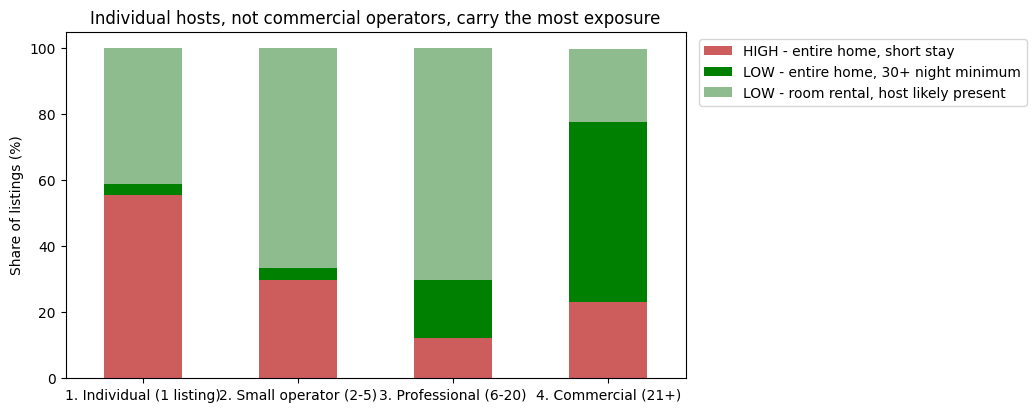

In [50]:
risk_order = ['HIGH - entire home, short stay',
              'LOW - entire home, 30+ night minimum',
              'LOW - room rental, host likely present']

risk_by_host_pct[risk_order].plot(kind='bar', stacked=True, figsize=(8, 4.5),
                                  color=['indianred', 'green', 'darkseagreen'])
plt.title('Individual hosts, not commercial operators, carry the most exposure')
plt.xlabel('')
plt.ylabel('Share of listings (%)')
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.savefig('images/chart5_regulatory_risk.png', dpi=150, bbox_inches='tight')
plt.show()

### Insight — the exposure is large, and it sits with the *opposite* group to the one we expected

**The headline numbers:**

| Category | Listings | Share of listings | Active listings | Revenue | **Share of revenue** |
|---|---|---|---|---|---|
| **HIGH – entire home, short stay** | 22,252 | **45.52%** | 11,928 | **$484.9m** | **67.5%** |
| LOW – room rental, host present | 23,477 | 48.03% | 12,439 | $194.0m | 27.0% |
| LOW – entire home, 30+ nights | 3,155 | 6.45% | 1,780 | $39.4m | 5.5% |

* **45.5% of listings are HIGH-risk, but they generate 67.5% of revenue.** Exposure measured
  in dollars is far worse than exposure measured in listings — because entire homes carry the
  highest rates. Anyone assessing this on listing counts alone will understate it by ~22 points.
* Only **9.2% of listings require a 30+ night stay** citywide.
* Geographically the exposure concentrates in **Manhattan (49.9% HIGH)** and Brooklyn (44.4%),
  versus the Bronx (32.9%) and Queens (35.2%) — i.e. in the two boroughs with the most
  political attention.

**🚨 And now the finding that reverses the conventional narrative.** The host cross-tab:

| Host segment | HIGH-risk % | 30+ night minimum % | Room rental % |
|---|---|---|---|
| **1. Individual (1 listing)** | **55.5%** | 3.3% | 41.2% |
| 2. Small operator (2–5) | 29.7% | 3.6% | 66.7% |
| 3. Professional (6–20) | **12.3%** | 17.6% | 70.1% |
| **4. Commercial (21+)** | 23.0% | **54.8%** | 22.1% |

**Individual, single-listing hosts are the most exposed group (55.5% HIGH-risk) — and
commercial operators are among the least.** More than half of commercial listings already
require a 30+ night minimum, versus just 3.3% of individual listings.

The interpretation is straightforward and important: **commercial operators have already
restructured for compliance.** They have legal advice, they read the regulations, and they
have moved into the legal long-stay/corporate-housing model. Individual hosts — who have no
legal counsel and may not know the rule exists — have not.

This means the common political framing ("commercial operators are exploiting the housing
stock via short-term lets") is **not supported by this data**. The short-stay entire-home
exposure is overwhelmingly an *ordinary-homeowner* phenomenon.

* Finally, `minimum_nights` contains **14 listings requiring more than 365 nights**, with a
  maximum of **1,250**. These are data errors and must be excluded before any figure enters a
  legal filing — a regulator finding an obvious error in our submission would discredit the rest.

### Recommendation
1. **Retarget the compliance campaign at individual hosts, not commercial ones.** This is the
   single most consequential correction in this notebook. A campaign aimed at commercial
   operators would spend effort on the **already-compliant** segment while leaving 55.5% of
   individual-host listings exposed. Individual hosts need *education* (most likely do not know
   the 30-night rule); commercial hosts need nothing.
2. **Use the commercial cohort as the proof-of-concept, and as the public argument.** They
   demonstrate that a 30+ night model is commercially viable — that is both the template for
   the host-education campaign *and* strong evidence for regulators that the platform's
   professional supply has adapted rather than evaded.
3. **Quantify and disclose proactively, in revenue terms.** 67.5% of NYC revenue sits in the
   HIGH category. It is far better for Airbnb to characterise that with correct numbers and
   context than for a regulator to reconstruct it from scraped data.
4. **Model full-enforcement revenue impact now.** The scenario to plan against is not "some
   listings are removed" but "**two-thirds of NYC revenue is restructured**".
5. **Fix `minimum_nights` data quality before any regulatory submission** — add an input
   validation rule (1 ≤ minimum_nights ≤ 365).

## STEP 11 — Dormant supply: when did listings last transact?

In [51]:
# last_review is text. Convert it to a real datetime to unlock the .dt accessor.
listings_valid['last_review'] = pd.to_datetime(listings_valid['last_review'], errors='coerce')

print('dtype        :', listings_valid['last_review'].dtype)
print('Earliest     :', listings_valid['last_review'].min())
print('Latest       :', listings_valid['last_review'].max())
print('Still null   :', listings_valid['last_review'].isnull().sum(),
      '(never-reviewed listings - correct, not an error)')

dtype        : datetime64[ns]
Earliest     : 2011-03-28 00:00:00
Latest       : 2019-07-08 00:00:00
Still null   : 10051 (never-reviewed listings - correct, not an error)


In [52]:
# .dt.year extracts the year from every value at once.
listings_valid['last_review_year'] = listings_valid['last_review'].dt.year

print('Listings by year of last review:')
print(listings_valid.groupby('last_review_year')['id'].count())

Listings by year of last review:
last_review_year
2011.0        7
2012.0       25
2013.0       48
2014.0      199
2015.0     1393
2016.0     2707
2017.0     3204
2018.0     6048
2019.0    25202
Name: id, dtype: int64


In [53]:
# The snapshot was taken in 2019, so anything last reviewed before 2019 is stale.
SNAPSHOT_YEAR = 2019

reviewed = listings_valid.loc[listings_valid['last_review'].notna()]
stale    = reviewed.loc[reviewed['last_review_year'] < SNAPSHOT_YEAR]

print('Listings with at least one review :', reviewed.shape[0])
print('Last reviewed BEFORE 2019 (stale) :', stale.shape[0],
      '->', round(stale.shape[0] / reviewed.shape[0] * 100, 1), '% of reviewed listings')
print()
print('Of those, last reviewed before 2017 (long dormant) :',
      reviewed.loc[reviewed['last_review_year'] < 2017].shape[0])

Listings with at least one review : 38833
Last reviewed BEFORE 2019 (stale) : 13631 -> 35.1 % of reviewed listings

Of those, last reviewed before 2017 (long dormant) : 4379


In [54]:
# .dt.month_name() and .dt.day_name() give the human-readable calendar labels.
listings_valid['last_review_month'] = listings_valid['last_review'].dt.month_name()
listings_valid['last_review_day']   = listings_valid['last_review'].dt.day_name()

print('Review activity by month (seasonality of NYC demand):')
print(listings_valid['last_review_month'].value_counts())
print()
print('Review activity by day of week:')
print(listings_valid['last_review_day'].value_counts())

Review activity by month (seasonality of NYC demand):
last_review_month
June         13584
July          5937
May           4699
January       2771
April         2109
December      1770
August        1667
October       1545
September     1535
March         1288
November      1158
February       770
Name: count, dtype: int64

Review activity by day of week:
last_review_day
Sunday       9381
Monday       7176
Saturday     5516
Tuesday      4738
Friday       4473
Wednesday    3995
Thursday     3554
Name: count, dtype: int64


### Insight — a third of reviewed listings are stale

* **38,833 listings have at least one review.** Of those, **13,631 (35.1%) were last
  reviewed before 2019** — and **4,379 were last reviewed before 2017**, i.e. dormant for
  two-plus years while still appearing in the public listing count.
* This **independently corroborates Step 7**. Two unrelated columns — `availability_365`
  and `last_review` — both say roughly a third of the marketplace is not trading. When two
  independent measures agree, the conclusion is solid.
* `notna()` is used deliberately here: nulls in `last_review` are *meaningful* (never
  reviewed), so we must separate "never reviewed" from "reviewed long ago". Collapsing them
  would merge two completely different business problems — a funnel failure and a churn failure.

### 🚨 Insight — the monthly pattern is NOT seasonality (trap number three)

The month counts look like a demand curve — **June 13,584, July 5,937, May 4,699**, falling
away to February 770 — and the tempting read is *"NYC demand peaks in early summer."*

**That read is wrong, and for a structural reason.** `last_review` is by definition each
listing's **most recent** review. The snapshot was taken in **mid-2019**, so every actively
trading listing has its last review clustered in the weeks *immediately before the snapshot
date*. The "peak" is measuring **proximity to the extraction date**, not seasonal demand.

The giveaway is the shape: a genuine seasonal curve would be smooth and roughly symmetric
across the year. This one decays monotonically backwards from the snapshot month —
the signature of a recency artifact.

The same caution applies to the weekday counts (Sunday 9,381, Monday 7,176): plausible as a
post-checkout review pattern, but confounded by the same recency effect and not safe to use.

### Recommendation
1. **Add a `last_transaction_recency` field to the supply dashboard** with explicit buckets
   (0–3 months, 3–12 months, 12+ months, never). This makes dormancy visible without
   requiring anyone to recompute it — and it is the *correct* use of this column.
2. **Auto-archive listings dormant for 24+ months** (4,379 of them), with a host
   re-confirmation email. It cleans the marketplace, improves guest search quality, and makes
   the supply number honest.
3. **Do NOT build seasonal pricing guidance from this column.** Seasonality requires the
   **full review history** (every review with its date), not the last-review date. Using
   `last_review` would tell Airbnb to raise prices in June because June is when the data was
   pulled — a self-inflicted error with real revenue consequences. Request the full reviews
   table before attempting seasonal guidance.

## STEP 12 — Executive scorecard and export

In [55]:
total_listings   = listings.shape[0]
valid_listings   = listings_valid.shape[0]
n_active         = active.shape[0]
pct_active       = round(n_active / valid_listings * 100, 1)
pct_zero_avail   = round((listings_valid['availability_365'] == 0).mean() * 100, 1)
pct_never_rev    = round((listings_valid['number_of_reviews'] == 0).mean() * 100, 1)
pct_stale        = round(stale.shape[0] / reviewed.shape[0] * 100, 1)
pct_high_risk    = round((listings_valid['regulatory_risk'] == 'HIGH - entire home, short stay').mean() * 100, 1)
pct_30plus       = round((listings_valid['minimum_nights'] >= 30).mean() * 100, 1)
pct_multi_host   = round((listings_valid['calculated_host_listings_count'] > 1).mean() * 100, 1)
max_host         = int(listings_valid['calculated_host_listings_count'].max())
rev_bn           = round(active['annual_revenue'].sum() / 1e9, 2)
naive_bn         = round(naive['annual_revenue'].sum() / 1e9, 2)

scorecard = pd.DataFrame({
    'metric': ['Listings in raw file',
               'Valid listings (price > $0)',
               'Active, review-verified listings',
               'Active share of valid listings (%)',
               'Listings with ZERO availability (%)',
               'Listings never reviewed (%)',
               'Reviewed listings that are stale, pre-2019 (%)',
               'Median nightly price, guidance frame ($)',
               'Mean nightly price, raw ($)',
               'MAD of price, raw ($)',
               'Std dev of price, raw ($)',
               'IQR upper outlier fence ($)',
               'Listings above the outlier fence (%)',
               'HIGH regulatory-risk listings (%)',
               'Listings requiring 30+ night stays (%)',
               'Listings held by multi-listing hosts (%)',
               'Largest single-host portfolio',
               'Estimated annual revenue, defensible ($bn)',
               'Estimated annual revenue, naive ($bn)'],
    'value':  [total_listings, valid_listings, n_active, pct_active,
               pct_zero_avail, pct_never_rev, pct_stale,
               guidance['price'].median(), round(listings['price'].mean(), 2),
               round(stats.median_abs_deviation(listings['price']), 2),
               round(listings['price'].std(), 2), upper_fence,
               round(high_outliers.shape[0] / listings.shape[0] * 100, 2),
               pct_high_risk, pct_30plus, pct_multi_host, max_host,
               rev_bn, naive_bn]
})

scorecard['flag'] = ['-', '-', '-', 'RISK', 'RISK', 'RISK', 'RISK',
                     'GOOD', 'WATCH', 'GOOD', 'RISK', '-', 'WATCH',
                     'RISK', 'RISK', 'WATCH', 'RISK', '-', 'REJECTED']
scorecard

,metric,value,flag
0,Listings in raw file,48895.00,-
1,Valid listings (price > $0),48884.00,-
2,"Active, review-verified listings",26147.00,-
3,Active share of valid listings (%),53.50,RISK
4,Listings with ZERO availability (%),35.90,RISK
5,Listings never reviewed (%),20.60,RISK
6,"Reviewed listings that are stale, pre-2019 (%)",35.10,RISK
7,"Median nightly price, guidance frame ($)",100.00,GOOD
8,"Mean nightly price, raw ($)",152.72,WATCH
9,"MAD of price, raw ($)",46.00,GOOD


In [56]:
scorecard.to_csv('airbnb_nyc_executive_scorecard.csv', sep=',', index=False)
median_grid.to_csv('airbnb_nyc_pricing_grid_median.csv', sep=',')
reliable.sort_values('median_price', ascending=False).to_csv(
    'airbnb_nyc_neighbourhood_benchmarks.csv', sep=',', index=False)
rev.to_csv('airbnb_nyc_revenue_by_borough.csv', sep=',', index=False)
health_pct_borough.to_csv('airbnb_nyc_supply_health_by_borough.csv', sep=',')
risk_by_borough.to_csv('airbnb_nyc_regulatory_exposure.csv', sep=',')
cleaning_log.to_csv('airbnb_nyc_cleaning_log.csv', sep=',', index=False)

print('Exported 7 CSV deliverables.')

Exported 7 CSV deliverables.


---
# STEP 13 — EXECUTIVE SUMMARY
---

## Answers to the three problems

### Problem 1 — "Our pricing guidance is wrong." **Confirmed.**

The guidance engine was anchored on the **mean ($152.72)** when the correct anchor is the
**median ($106, or $100 in the cleaned guidance frame)**. The proof is statistical, not
anecdotal: the **standard deviation ($240) is 5.2× the MAD ($46)**, which only happens
when a small tail of extreme values dominates every mean-based statistic.

The mean over-states the median in **every single borough × room-type cell** — so the
Bronx hosts complaining that guidance was "laughably high" were literally correct. And the
over-statement is **largest in the cheapest boroughs** (Staten Island +$21.1, Bronx +$12.2
on entire homes) and **smallest in Manhattan** (+$6.70), which explains exactly why the
complaints came from where they did.

**Fix:** rebuild Smart Pricing on the median grid, segmented by **room type first**
(room type turns out to matter more than borough — a $100 entire home in the Bronx beats
an $89 private room in Manhattan), publish MAD as the range, and suppress guidance in
low-volume cells (Staten Island has just **9** shared rooms).

### Problem 2 — "We don't trust our supply numbers." **Confirmed, and worse than suspected.**

The headline **48,895 listings** is not bookable supply. Only **19,141 (39.2%) are
genuinely active** — an overstatement of **~2.6×**:

* **35.9% have zero availability** — and we proved by cross-checking review activity that
  these are **dormant, not sold out**. The zero-availability cohort gets **0.08 reviews per
  month versus 0.92** for available listings. A fully-booked listing would be the *most*
  reviewed; these are the *least*.
* **20.6% have never received a single review** — likely never hosted a guest.
* **35.1% of reviewed listings were last reviewed before 2019**; 4,379 before 2017.
  *Two independent columns agree*, which is what makes the conclusion solid.
* **The premium boroughs are the sickest:** Manhattan is only **35.2% active** and Brooklyn
  38.7%, versus Staten Island 64.1% and the Bronx 55.5%.

The naive revenue model handed those 17,530 dormant listings a **perfect 365-night year**,
producing **$1.76bn** at a 69.1% citywide occupancy rate. The defensible estimate is
**$0.72bn at 53.3%** — the naive figure was **2.4× too high**.

**Fix:** make "active, review-verified listings" the headline supply KPI *by borough*;
launch host reactivation (cheaper than acquisition — onboarding is already paid for);
auto-archive 24-month dormant listings.

### Problem 3 — "How exposed are we to NYC regulation?" **Biggest risk in the data — and the exposure sits with the opposite group to the one everyone assumes.**

* **45.5% of listings are HIGH-risk** (entire home, under 30 nights) — but they generate
  **67.5% of revenue ($484.9m)**. Measured in listings the exposure looks like half the
  market; measured in dollars it is **two-thirds**.
* Concentrated in **Manhattan (49.9% HIGH)** and Brooklyn (44.4%).
* **🚨 The reversal:** **individual single-listing hosts are the most exposed (55.5%
  HIGH-risk)**, while **commercial 21+ hosts are among the least — 54.8% of their listings
  already require a 30+ night minimum**, versus just 3.3% of individual listings.
  **Commercial operators have already restructured for compliance; ordinary homeowners have
  not.** The political framing that commercial operators drive short-term-let exposure is
  **not supported by this data**.
* Only **9.2%** of listings citywide require 30+ night stays.

**Fix:** **retarget the compliance campaign at individual hosts** — aiming it at commercial
operators would spend the entire budget on the already-compliant segment. Use the commercial
cohort as both the viability template and the public evidence that professional supply
adapted rather than evaded. Model the "two-thirds of NYC revenue restructured" scenario now.
Fix the `minimum_nights` data errors (14 listings demand >365 nights, max **1,250**) before
anything enters a legal filing.

---

## The three methodological traps this notebook caught

All three would have produced confidently wrong answers:

1. **Structural vs random missingness.** `reviews_per_month` was missing for *exactly* the
   10,052 zero-review listings — a perfect match, verified with `np.all()`. So the "missing"
   value was a **known value (0)**, not an unknown one. Imputing a mean there would have
   invented review activity for listings that never hosted anyone.
2. **`availability_365 == 0` is ambiguous.** It reads as "fully booked" but means
   "calendar closed". We settled it with an independent column (reviews) rather than an
   assumption — the difference between a $0.72bn estimate and a $1.76bn one.
3. **`last_review` months look like seasonality but are a recency artifact.** Because
   `last_review` is by definition the *most recent* review, active listings cluster in the
   weeks before the extraction date. "June is peak season" was really "June is when the
   file was pulled." Acting on it would have raised prices in the wrong month.

## And one place where the hypothesis was simply wrong

We went into Step 10 expecting commercial operators to be the regulatory problem — that is
the standard narrative. **The data said the opposite.** Had we written the recommendation
from the prior rather than from the cross-tab, the compliance campaign would have been
aimed at the one segment that had already solved the problem. Cross-tabulating a risk flag
against a customer segmentation cost two lines of code and changed the entire action.

> **The transferable lesson:** the mean, the standard deviation, and the 1.5×IQR rule are
> all *tools with assumptions*. The IQR rule handed us a **lower fence of −$90** — valid
> arithmetic, meaningless economics — and simultaneously **missed the 11 genuinely invalid
> $0 listings**. Statistics do not fail loudly. They fail quietly, and produce a number
> that looks perfectly presentable.

## Assumptions and limitations

* **Single 2019 snapshot.** No time series, so we cannot separate trend from seasonality.
* **`availability_365` is a forward-looking calendar field**, not a booking record. Every
  occupancy and revenue figure here is a **reasoned proxy** and is labelled as such.
* **Reviews are a proxy for stays**, not a measurement. Not every guest reviews, so review
  counts understate activity by an unknown factor.
* **`price` is the advertised nightly rate.** It excludes cleaning fees, service fees,
  discounts and taxes, so it is not realised revenue per night.
* **No cost data**, so nothing here speaks to host *profitability*.
* Legal interpretation of NYC short-term-rental rules is simplified to
  *entire home + under 30 nights*. Actual compliance depends on host presence,
  registration status and building class, which this dataset does not contain.